<a href="https://colab.research.google.com/github/Isadora220825/PSP-8---Telco-Customer-Churn/blob/main/Trabalho_PSP8_churn_tradicional_vs_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise Tradicional × Inteligência Artificial: prever e prevenir o cancelamento de clientes

**Base:** Telco Customer Churn (Kaggle — `blastchar/telco-customer-churn`), 7.043 clientes de uma operadora, com perfil, serviços contratados, forma de pagamento e se cancelaram (*churn*) ou não.

**Pergunta do projeto:** mecanismos de inteligência (aprendizado de máquina) melhoram as análises e respostas que uma análise tradicional (estatística descritiva + regras de negócio) produz?

**Como vamos constatar:** em vez de rodar só um modelo, montamos **pares** — a mesma pergunta de negócio respondida das duas formas, com os mesmos dados de teste e a mesma métrica:

| Par | Tipo de análise | Pergunta de negócio | Abordagem tradicional | Mecanismo de inteligência | Como comparamos |
|---|---|---|---|---|---|
| 1 | Preditiva | Quem vai cancelar? | Regra de pontuação de risco montada a partir de tabelas cruzadas | Regressão Logística, Random Forest e Gradient Boosting | Acurácia, precisão, recall, F1, AUC + teste de McNemar |
| 2 | Preditiva → decisão | Quem priorizar numa campanha de retenção com orçamento limitado? | Ordenar pela pontuação de risco | Ordenar pela probabilidade prevista | Lift / % de churners capturados no top 20% e resultado financeiro simulado |
| 3 | Descritiva / diagnóstica | Quais fatores explicam o cancelamento? | Diferença de taxa de churn por categoria | Importância por permutação no melhor modelo | Ranking dos fatores e o que cada abordagem revela |
| 4 | Descritiva | Como segmentar a base? | Faixas manuais de tempo de casa | Clusterização K-Means | Quão bem os segmentos separam o risco |
| 5 | **Prescritiva** | Qual ação oferecer a cada cliente, dentro do orçamento? | Mesma oferta para todos os clientes de risco (regra de negócio) | Simulação "e se?" com o modelo + otimização da ação por cliente sob orçamento | Retorno líquido esperado (R$), clientes retidos e ROI do plano |

**Os quatro níveis de análise cobertos:**
- **Descritiva** (o que aconteceu?): Etapa 4 e Par 4 — taxas, distribuições e segmentos.
- **Diagnóstica** (por que aconteceu?): Par 3 — quais fatores pesam no cancelamento.
- **Preditiva** (o que vai acontecer?): Pares 1 e 2 — probabilidade de cada cliente cancelar.
- **Prescritiva** (o que devo fazer?): Par 5 — qual ação aplicar a cada cliente e quanto isso deve render.

O resultado final do notebook é um **plano de ação exportável** (CSV): lista de clientes, risco, ação recomendada e ganho esperado.

> Regra de ouro do experimento: **todas as regras e modelos são construídos só com os dados de treino** e avaliados nos dados de teste, que nenhum dos dois lados "viu". Assim a comparação é justa.

## Etapa 1 — Preparar o ambiente
Importamos as bibliotecas. No Colab todas já vêm instaladas, exceto talvez o `kagglehub`, que instalamos na primeira linha.

In [1]:
!pip install -q kagglehub  # instala silenciosamente (-q) a biblioteca oficial do Kaggle para baixar bases

import numpy as np  # biblioteca de cálculo numérico (vetores, matrizes, médias etc.)
import pandas as pd  # biblioteca de tabelas (DataFrames), base de toda a análise
import matplotlib.pyplot as plt  # biblioteca de gráficos
import seaborn as sns  # camada sobre o matplotlib que deixa gráficos estatísticos mais simples e bonitos
from scipy.stats import chi2  # distribuição qui-quadrado, usada no teste de McNemar

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score  # divisão treino/teste e validação cruzada
from sklearn.compose import ColumnTransformer  # aplica transformações diferentes em colunas diferentes
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # codifica categorias em 0/1 e padroniza números
from sklearn.pipeline import Pipeline  # encadeia pré-processamento + modelo num único objeto
from sklearn.linear_model import LogisticRegression  # modelo 1: regressão logística (simples e interpretável)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier  # modelos 2 e 3: conjuntos de árvores de decisão
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # métricas de classificação
                             roc_auc_score, roc_curve, confusion_matrix, silhouette_score)  # AUC, curva ROC, matriz de confusão, qualidade de cluster
from sklearn.inspection import permutation_importance  # mede a importância de cada variável embaralhando-a
from sklearn.cluster import KMeans  # algoritmo de clusterização (segmentação automática)

import warnings  # módulo padrão para controlar avisos
warnings.filterwarnings('ignore')  # esconde avisos que não afetam o resultado, para o notebook ficar limpo

SEED = 42  # semente aleatória fixa: garante que todo mundo que rodar o notebook obtenha os mesmos números
sns.set_theme(style='whitegrid')  # define um estilo visual limpo para todos os gráficos
pd.set_option('display.max_columns', 50)  # mostra até 50 colunas ao exibir tabelas
print('Ambiente pronto!')  # confirma que tudo foi importado sem erro

Ambiente pronto!


## Etapa 2 — Baixar a base do Kaggle
**Opção A (automática):** o `kagglehub` baixa a base pública direto do Kaggle. Se pedir login, siga a Opção B.

**Opção B (manual):** entre em kaggle.com/datasets/blastchar/telco-customer-churn → *Download* → descompacte → rode a célula seguinte que abre o seletor de arquivos e envie o `WA_Fn-UseC_-Telco-Customer-Churn.csv`.

In [2]:
import os, glob  # módulos padrão para lidar com caminhos e procurar arquivos

ARQUIVO = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'  # nome do arquivo CSV dentro da base do Kaggle
caminho_csv = None  # começa vazio; será preenchido quando o arquivo for encontrado

try:  # tenta a Opção A
    import kagglehub  # importa a biblioteca do Kaggle
    pasta = kagglehub.dataset_download('blastchar/telco-customer-churn')  # baixa a base e devolve a pasta onde ela foi salva
    caminho_csv = glob.glob(os.path.join(pasta, '**', '*.csv'), recursive=True)[0]  # procura o CSV dentro da pasta baixada
    print('Base baixada pelo kagglehub em:', caminho_csv)  # mostra onde o arquivo está
except Exception as erro:  # se algo deu errado (sem internet, login etc.)
    print('Download automático falhou:', erro)  # mostra o motivo
    print('Use a Opção B: rode a próxima célula e envie o CSV manualmente.')  # orienta o próximo passo

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Base baixada pelo kagglehub em: /kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
# Rode esta célula APENAS se a anterior falhou (Opção B)
if caminho_csv is None and not os.path.exists(ARQUIVO):  # só abre o upload se o arquivo ainda não estiver disponível
    from google.colab import files  # ferramenta do Colab para enviar arquivos do seu computador
    enviado = files.upload()  # abre a janela de seleção de arquivo
    caminho_csv = list(enviado.keys())[0]  # guarda o nome do arquivo enviado
elif caminho_csv is None:  # se o arquivo já está na pasta do Colab
    caminho_csv = ARQUIVO  # usa ele diretamente
print('Arquivo que será usado:', caminho_csv)  # confirma o caminho final

Arquivo que será usado: /kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


## Etapa 3 — Conhecer e limpar os dados

In [4]:
df = pd.read_csv(caminho_csv)  # lê o CSV e transforma numa tabela (DataFrame)
print('Linhas e colunas:', df.shape)  # mostra quantos clientes (linhas) e variáveis (colunas) existem
df.head()  # exibe as 5 primeiras linhas para termos uma ideia do conteúdo

Linhas e colunas: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()  # lista cada coluna, seu tipo (texto, número) e quantos valores não nulos ela tem

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# A coluna TotalCharges veio como texto porque clientes novos têm um espaço em branco no lugar do valor
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')  # converte para número; o que não for número vira NaN (vazio)
print('Valores vazios em TotalCharges:', df['TotalCharges'].isna().sum())  # conta quantos ficaram vazios
df['TotalCharges'] = df['TotalCharges'].fillna(0)  # clientes com tenure 0 ainda não pagaram nada, então o total gasto é 0

df = df.drop(columns=['customerID'])  # remove o ID do cliente: é só um identificador e não ajuda a prever nada
df['Churn'] = (df['Churn'] == 'Yes').astype(int)  # transforma o alvo em número: 1 = cancelou, 0 = ficou
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})  # deixa "idoso" como categoria (Yes/No), igual às outras colunas

print('Taxa geral de churn: {:.1%}'.format(df['Churn'].mean()))  # média do alvo 0/1 = proporção de clientes que cancelaram

Valores vazios em TotalCharges: 11
Taxa geral de churn: 26.5%


### Separar treino e teste (antes de qualquer análise!)
Separamos 25% dos clientes como **teste**. A análise tradicional e os modelos só podem olhar o **treino**. É isso que torna a comparação honesta: se a regra tradicional fosse criada olhando o teste, ela teria vantagem injusta.

In [7]:
X = df.drop(columns=['Churn'])  # X = todas as variáveis explicativas (características do cliente)
y = df['Churn']  # y = o que queremos prever (cancelou ou não)

X_treino, X_teste, y_treino, y_teste = train_test_split(  # divide a base em duas partes
    X, y,  # dados que serão divididos
    test_size=0.25,  # 25% vai para teste, 75% para treino
    stratify=y,  # mantém a mesma proporção de churn nas duas partes
    random_state=SEED)  # semente fixa para a divisão ser sempre a mesma

treino = X_treino.assign(Churn=y_treino)  # junta X e y do treino numa tabela só, para facilitar a análise descritiva
print('Treino:', X_treino.shape[0], 'clientes | Teste:', X_teste.shape[0], 'clientes')  # confere os tamanhos
print('Churn no treino: {:.1%} | no teste: {:.1%}'.format(y_treino.mean(), y_teste.mean()))  # confere que as proporções ficaram iguais

Treino: 5282 clientes | Teste: 1761 clientes
Churn no treino: 26.5% | no teste: 26.5%


## Etapa 4 — Análise tradicional `[DESCRITIVA]`
É o que um analista faria em Excel/BI: taxa de churn por categoria, tabelas cruzadas e gráficos. Tudo feito **só no treino**.

In [8]:
colunas_categoricas = X.select_dtypes(include='object').columns.tolist()  # lista das colunas de texto (categorias)
colunas_numericas = X.select_dtypes(exclude='object').columns.tolist()  # lista das colunas numéricas
print('Categóricas:', colunas_categoricas)  # mostra as categóricas
print('Numéricas:', colunas_numericas)  # mostra as numéricas

Categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']


In [9]:
taxa_geral = treino['Churn'].mean()  # taxa média de churn no treino, usada como referência
linhas = []  # lista vazia que vai receber um resumo por categoria
for col in colunas_categoricas:  # percorre cada variável categórica
    resumo = treino.groupby(col)['Churn'].agg(['mean', 'count'])  # calcula taxa de churn e quantidade de clientes em cada categoria
    for categoria, valores in resumo.iterrows():  # percorre cada categoria daquela variável
        linhas.append({'variavel': col,  # nome da variável
                       'categoria': categoria,  # nome da categoria (ex.: Month-to-month)
                       'clientes': int(valores['count']),  # quantos clientes estão nessa categoria
                       'taxa_churn': valores['mean'],  # taxa de churn nessa categoria
                       'diferenca_vs_media': valores['mean'] - taxa_geral})  # quanto acima/abaixo da média ela está

tabela_tradicional = pd.DataFrame(linhas)  # transforma a lista numa tabela
tabela_tradicional = tabela_tradicional.sort_values('diferenca_vs_media', ascending=False)  # ordena das categorias mais arriscadas para as menos
tabela_tradicional.head(10).style.format({'taxa_churn': '{:.1%}', 'diferenca_vs_media': '{:+.1%}'})  # mostra as 10 categorias de maior risco com % formatado

,variavel,categoria,clientes,taxa_churn,diferenca_vs_media
41,PaymentMethod,Electronic check,1772,45.4%,+18.8%
34,Contract,Month-to-month,2907,42.7%,+16.1%
14,InternetService,Fiber optic,2323,42.0%,+15.5%
16,OnlineSecurity,No,2618,42.0%,+15.4%
25,TechSupport,No,2585,41.9%,+15.4%
3,SeniorCitizen,Yes,856,41.4%,+14.8%
19,OnlineBackup,No,2300,40.1%,+13.6%
22,DeviceProtection,No,2305,39.1%,+12.6%
38,PaperlessBilling,Yes,3132,33.9%,+7.4%
31,StreamingMovies,No,2077,33.6%,+7.1%


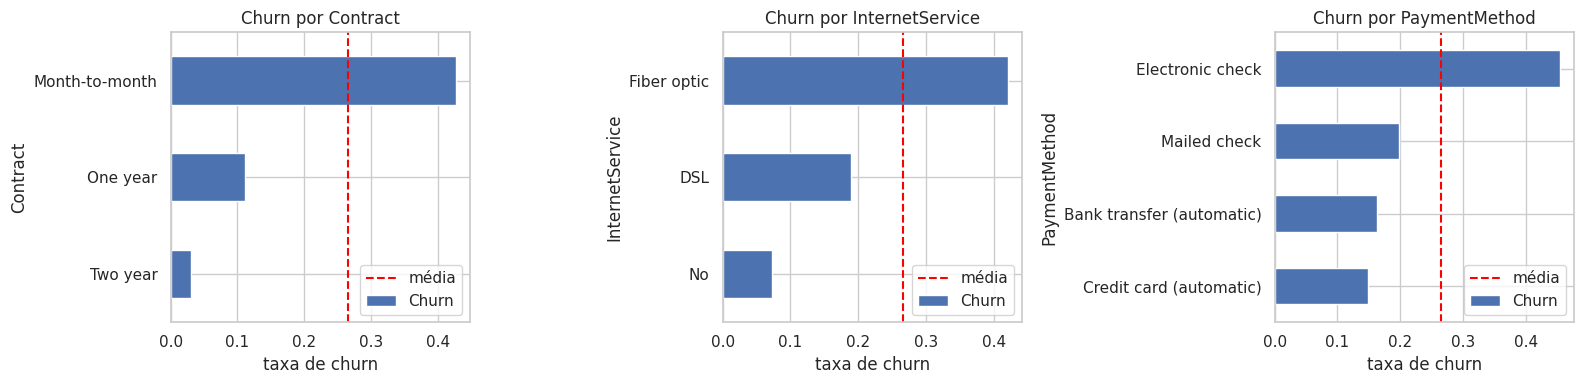

In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))  # cria uma figura com 3 gráficos lado a lado
for eixo, col in zip(eixos, ['Contract', 'InternetService', 'PaymentMethod']):  # para cada uma das 3 variáveis mais reveladoras
    taxas = treino.groupby(col)['Churn'].mean().sort_values()  # taxa de churn por categoria, em ordem crescente
    taxas.plot(kind='barh', ax=eixo, color='#4C72B0')  # desenha barras horizontais
    eixo.axvline(taxa_geral, color='red', linestyle='--', label='média')  # linha vermelha mostrando a média geral
    eixo.set_title('Churn por ' + col)  # título do gráfico
    eixo.set_xlabel('taxa de churn')  # rótulo do eixo X
    eixo.legend()  # mostra a legenda
plt.tight_layout()  # ajusta espaçamentos para nada ficar sobreposto
plt.show()  # exibe a figura

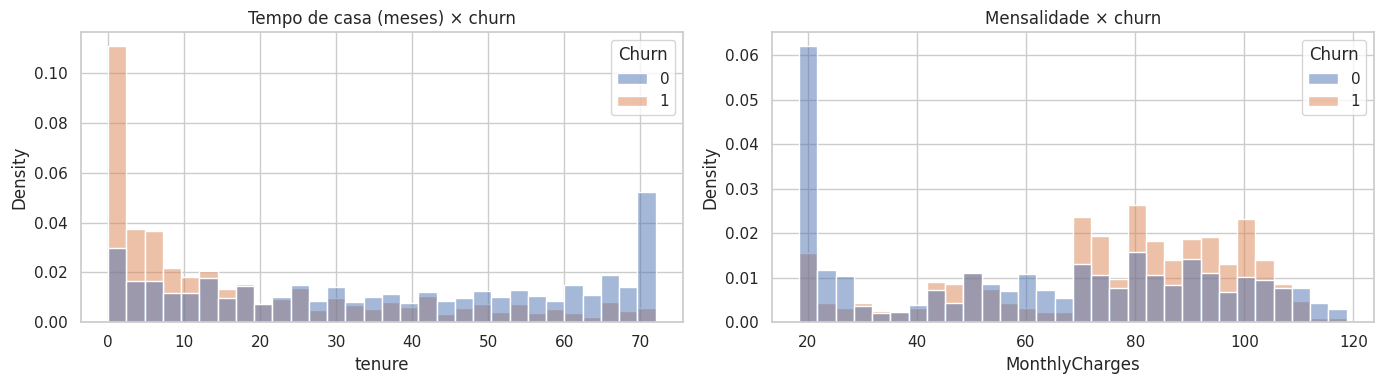

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))  # dois gráficos lado a lado para as variáveis numéricas
sns.histplot(data=treino, x='tenure', hue='Churn', bins=30, ax=eixos[0], stat='density', common_norm=False)  # distribuição do tempo de casa, separada por quem cancelou ou não
eixos[0].set_title('Tempo de casa (meses) × churn')  # título do primeiro gráfico
sns.histplot(data=treino, x='MonthlyCharges', hue='Churn', bins=30, ax=eixos[1], stat='density', common_norm=False)  # distribuição da mensalidade, separada por churn
eixos[1].set_title('Mensalidade × churn')  # título do segundo gráfico
plt.tight_layout()  # ajusta espaçamentos
plt.show()  # exibe a figura

**Conclusões típicas da análise tradicional** (confira nos seus números): contrato mensal, internet por fibra, pagamento por cheque eletrônico e pouco tempo de casa concentram o churn. Com isso o analista monta uma **regra de pontuação de risco**: 1 ponto por fator de risco; quem soma pontos suficientes é sinalizado.

In [12]:
def pontuacao_tradicional(dados):  # função que aplica a regra de negócio a qualquer tabela de clientes
    pontos = np.zeros(len(dados))  # começa todo mundo com 0 pontos
    pontos += (dados['Contract'] == 'Month-to-month').values  # +1 ponto se o contrato é mensal
    pontos += (dados['InternetService'] == 'Fiber optic').values  # +1 ponto se usa fibra
    pontos += (dados['PaymentMethod'] == 'Electronic check').values  # +1 ponto se paga por cheque eletrônico
    pontos += (dados['tenure'] < 12).values  # +1 ponto se é cliente há menos de 1 ano
    pontos += (dados['TechSupport'] == 'No').values  # +1 ponto se não tem suporte técnico
    return pontos  # devolve a pontuação de 0 a 5 de cada cliente

pontos_treino = pontuacao_tradicional(X_treino)  # calcula a pontuação dos clientes do treino
melhor_corte, melhor_f1 = None, -1  # variáveis para guardar o melhor ponto de corte encontrado
for corte in range(1, 6):  # testa cortes de 1 a 5 pontos
    previsao = (pontos_treino >= corte).astype(int)  # sinaliza como "vai cancelar" quem tem pontos >= corte
    f1 = f1_score(y_treino, previsao)  # mede o F1 desse corte no treino
    print(f'Corte >= {corte} pontos -> F1 no treino = {f1:.3f}')  # mostra o resultado de cada corte
    if f1 > melhor_f1:  # se este corte for o melhor até agora
        melhor_corte, melhor_f1 = corte, f1  # guarda ele
print('Corte escolhido para a regra tradicional:', melhor_corte)  # mostra o corte que a regra vai usar

Corte >= 1 pontos -> F1 no treino = 0.498
Corte >= 2 pontos -> F1 no treino = 0.565
Corte >= 3 pontos -> F1 no treino = 0.617
Corte >= 4 pontos -> F1 no treino = 0.585
Corte >= 5 pontos -> F1 no treino = 0.344
Corte escolhido para a regra tradicional: 3


## Etapa 5 — Mecanismos de inteligência (aprendizado de máquina)
Treinamos três modelos com **exatamente o mesmo treino**. O `Pipeline` garante que o pré-processamento (transformar categorias em 0/1 e padronizar números) seja aprendido só no treino.

In [13]:
preprocessador = ColumnTransformer([  # define como cada tipo de coluna será tratado
    ('num', StandardScaler(), colunas_numericas),  # números: padroniza (média 0, desvio 1) para ficarem na mesma escala
    ('cat', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas)])  # categorias: vira colunas 0/1; ignora categorias novas no teste

modelos = {  # dicionário com os três modelos que vamos comparar
    'Regressão Logística': LogisticRegression(max_iter=1000, class_weight='balanced'),  # linear; 'balanced' dá mais peso à classe minoritária (churn)
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,  # 300 árvores; cada folha com pelo menos 5 clientes (evita decorar)
                                            class_weight='balanced', random_state=SEED, n_jobs=-1),  # equilibra classes; usa todos os núcleos do processador
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,  # 200 árvores pequenas em sequência, cada uma corrigindo a anterior
                                                    max_depth=3, random_state=SEED)}  # árvores rasas (profundidade 3)

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # validação cruzada em 5 partes, mantendo a proporção de churn
pipelines = {}  # dicionário que vai guardar cada modelo já treinado
for nome, modelo in modelos.items():  # percorre cada modelo
    pipe = Pipeline([('prep', preprocessador), ('modelo', modelo)])  # junta pré-processamento + modelo
    auc_cv = cross_val_score(pipe, X_treino, y_treino, cv=validacao, scoring='roc_auc')  # AUC em cada uma das 5 partes do treino
    print(f'{nome:20s} AUC validação cruzada = {auc_cv.mean():.3f} ± {auc_cv.std():.3f}')  # média e variação: mostra se o modelo é estável
    pipe.fit(X_treino, y_treino)  # treina o modelo final com todo o treino
    pipelines[nome] = pipe  # guarda o modelo treinado

Regressão Logística  AUC validação cruzada = 0.844 ± 0.015
Random Forest        AUC validação cruzada = 0.844 ± 0.014
Gradient Boosting    AUC validação cruzada = 0.845 ± 0.013


In [14]:
limiares = {}  # guarda o melhor limiar de probabilidade de cada modelo
for nome, pipe in pipelines.items():  # para cada modelo treinado
    prob_cv = np.zeros(len(y_treino))  # vetor para guardar probabilidades "fora da amostra" do treino
    for idx_tr, idx_val in validacao.split(X_treino, y_treino):  # em cada dobra da validação cruzada
        copia = Pipeline([('prep', preprocessador), ('modelo', modelos[nome])])  # cria uma cópia nova do modelo
        copia.fit(X_treino.iloc[idx_tr], y_treino.iloc[idx_tr])  # treina só com parte do treino
        prob_cv[idx_val] = copia.predict_proba(X_treino.iloc[idx_val])[:, 1]  # prevê a parte que ficou de fora
    candidatos = np.arange(0.1, 0.9, 0.01)  # limiares candidatos de 0,10 a 0,89
    f1s = [f1_score(y_treino, (prob_cv >= t).astype(int)) for t in candidatos]  # F1 de cada limiar
    limiares[nome] = candidatos[int(np.argmax(f1s))]  # escolhe o limiar com maior F1 (mesmo critério usado na regra tradicional)
    print(f'{nome:20s} limiar escolhido = {limiares[nome]:.2f}')  # mostra o limiar de cada modelo

Regressão Logística  limiar escolhido = 0.57
Random Forest        limiar escolhido = 0.45
Gradient Boosting    limiar escolhido = 0.32


## PAR 1 `[PREDITIVA]` — Quem vai cancelar? (Regra tradicional × Modelos)
Agora, pela primeira vez, usamos o **teste**.

In [15]:
resultados = []  # lista para guardar as métricas de cada abordagem
previsoes = {}  # guarda as previsões 0/1 de cada abordagem (usadas no teste de McNemar)
scores = {}  # guarda as "notas" de risco contínuas de cada abordagem (usadas na curva ROC e no Par 2)

pontos_teste = pontuacao_tradicional(X_teste)  # aplica a regra tradicional aos clientes do teste
previsoes['Tradicional (regra)'] = (pontos_teste >= melhor_corte).astype(int)  # sinaliza quem atinge o corte
scores['Tradicional (regra)'] = pontos_teste  # a pontuação de 0 a 5 funciona como nota de risco

for nome, pipe in pipelines.items():  # para cada modelo
    prob = pipe.predict_proba(X_teste)[:, 1]  # probabilidade prevista de cancelar
    scores[nome] = prob  # guarda a probabilidade
    previsoes[nome] = (prob >= limiares[nome]).astype(int)  # converte em 0/1 usando o limiar escolhido no treino

for nome in previsoes:  # calcula as métricas para cada abordagem
    p = previsoes[nome]  # previsões 0/1
    resultados.append({'Abordagem': nome,  # nome da abordagem
                       'Acurácia': accuracy_score(y_teste, p),  # % de acertos no geral
                       'Precisão': precision_score(y_teste, p),  # dos que sinalizei, quantos realmente cancelaram
                       'Recall': recall_score(y_teste, p),  # dos que cancelaram, quantos eu consegui sinalizar
                       'F1': f1_score(y_teste, p),  # equilíbrio entre precisão e recall
                       'AUC': roc_auc_score(y_teste, scores[nome])})  # capacidade de ordenar quem tem mais risco (1 = perfeito, 0,5 = sorteio)

tabela_par1 = pd.DataFrame(resultados).set_index('Abordagem')  # transforma em tabela
tabela_par1.style.format('{:.3f}').highlight_max(color='#c6efce')  # mostra com 3 casas e destaca em verde o melhor de cada métrica

,Acurácia,Precisão,Recall,F1,AUC
Abordagem,,,,,
Tradicional (regra),0.738,0.503,0.790,0.615,0.820
Regressão Logística,0.766,0.543,0.737,0.625,0.846
Random Forest,0.761,0.534,0.769,0.630,0.842
Gradient Boosting,0.776,0.560,0.722,0.630,0.843


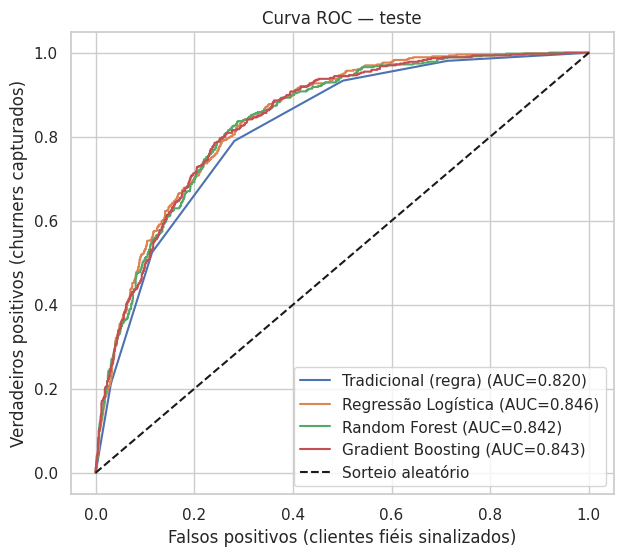

In [16]:
plt.figure(figsize=(7, 6))  # cria a figura da curva ROC
for nome, s in scores.items():  # para cada abordagem
    fpr, tpr, _ = roc_curve(y_teste, s)  # calcula taxa de falsos positivos e verdadeiros positivos em vários cortes
    plt.plot(fpr, tpr, label=f'{nome} (AUC={roc_auc_score(y_teste, s):.3f})')  # desenha a curva
plt.plot([0, 1], [0, 1], 'k--', label='Sorteio aleatório')  # diagonal = modelo que chuta
plt.xlabel('Falsos positivos (clientes fiéis sinalizados)')  # rótulo do eixo X
plt.ylabel('Verdadeiros positivos (churners capturados)')  # rótulo do eixo Y
plt.title('Curva ROC — teste')  # título
plt.legend()  # legenda
plt.show()  # exibe

Melhor mecanismo de inteligência: Gradient Boosting


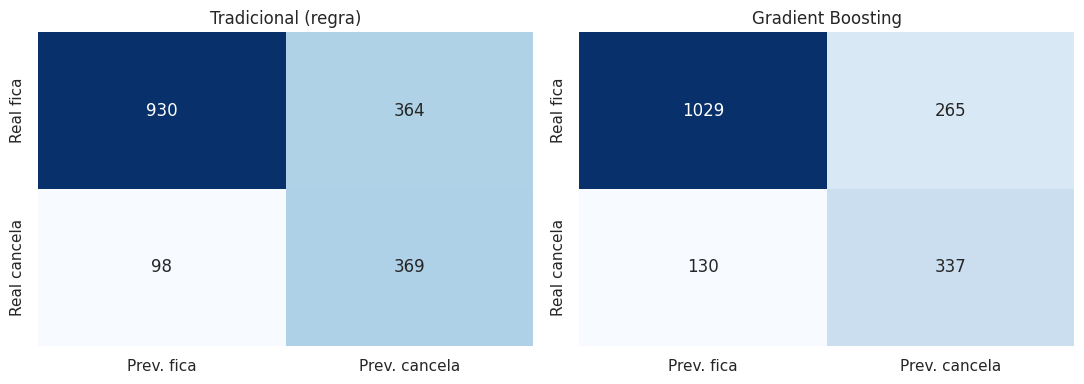

In [17]:
melhor_modelo = tabela_par1.drop('Tradicional (regra)')['F1'].idxmax()  # escolhe o modelo de maior F1 no teste
print('Melhor mecanismo de inteligência:', melhor_modelo)  # mostra qual foi

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))  # dois gráficos lado a lado
for eixo, nome in zip(eixos, ['Tradicional (regra)', melhor_modelo]):  # regra tradicional e melhor modelo
    mc = confusion_matrix(y_teste, previsoes[nome])  # matriz de confusão: acertos e erros por classe
    sns.heatmap(mc, annot=True, fmt='d', cmap='Blues', cbar=False, ax=eixo,  # desenha a matriz com os números
                xticklabels=['Prev. fica', 'Prev. cancela'], yticklabels=['Real fica', 'Real cancela'])  # nomes das linhas e colunas
    eixo.set_title(nome)  # título de cada matriz
plt.tight_layout()  # ajusta espaçamento
plt.show()  # exibe

### Constatando estatisticamente: teste de McNemar
A diferença de desempenho pode ser sorte. O **teste de McNemar** compara os acertos das duas abordagens **nos mesmos clientes**:
- *b* = clientes que a regra acertou e o modelo errou; *c* = o modelo acertou e a regra errou.
- Se *p-valor < 0,05*, a diferença é estatisticamente significativa (dificilmente é acaso).

In [18]:
def teste_mcnemar(y_real, prev_a, prev_b):  # função que compara duas abordagens nos mesmos clientes
    acerto_a = (prev_a == y_real)  # True onde a abordagem A acertou
    acerto_b = (prev_b == y_real)  # True onde a abordagem B acertou
    b = int(np.sum(acerto_a & ~acerto_b))  # A acertou e B errou
    c = int(np.sum(~acerto_a & acerto_b))  # A errou e B acertou
    estatistica = (abs(b - c) - 1) ** 2 / (b + c) if (b + c) > 0 else 0.0  # estatística de McNemar com correção de continuidade
    p_valor = chi2.sf(estatistica, df=1)  # probabilidade de ver essa diferença por acaso (qui-quadrado com 1 grau de liberdade)
    return b, c, estatistica, p_valor  # devolve tudo

for nome in pipelines:  # compara a regra tradicional com cada modelo
    b, c, est, p = teste_mcnemar(y_teste.values, previsoes['Tradicional (regra)'], previsoes[nome])  # roda o teste
    conclusao = 'diferença SIGNIFICATIVA' if p < 0.05 else 'diferença NÃO significativa'  # interpreta o p-valor
    print(f'Regra × {nome:20s} | só regra acertou={b:4d} | só modelo acertou={c:4d} | p={p:.4f} -> {conclusao}')  # mostra o resultado

Regra × Regressão Logística  | só regra acertou=  69 | só modelo acertou= 119 | p=0.0004 -> diferença SIGNIFICATIVA
Regra × Random Forest        | só regra acertou=  84 | só modelo acertou= 125 | p=0.0057 -> diferença SIGNIFICATIVA
Regra × Gradient Boosting    | só regra acertou=  82 | só modelo acertou= 149 | p=0.0000 -> diferença SIGNIFICATIVA


In [19]:
# Bootstrap: quanto o F1 do melhor modelo supera o da regra, com intervalo de confiança de 95%
rng = np.random.default_rng(SEED)  # gerador de números aleatórios com semente fixa
y_arr = y_teste.values  # rótulos reais do teste como vetor
dif_f1 = []  # lista com a diferença de F1 em cada reamostragem
for _ in range(1000):  # repete 1000 vezes
    idx = rng.integers(0, len(y_arr), len(y_arr))  # sorteia clientes do teste com reposição
    f1_modelo = f1_score(y_arr[idx], previsoes[melhor_modelo][idx])  # F1 do modelo nessa amostra
    f1_regra = f1_score(y_arr[idx], previsoes['Tradicional (regra)'][idx])  # F1 da regra nessa amostra
    dif_f1.append(f1_modelo - f1_regra)  # guarda a diferença
ic_baixo, ic_alto = np.percentile(dif_f1, [2.5, 97.5])  # pega os percentis que formam o intervalo de 95%
print(f'Ganho de F1 do {melhor_modelo} sobre a regra: {np.mean(dif_f1):+.3f}  (IC 95%: {ic_baixo:+.3f} a {ic_alto:+.3f})')  # mostra o ganho médio e o intervalo
print('O intervalo não inclui zero -> ganho consistente.' if ic_baixo > 0 else 'O intervalo inclui zero -> ganho não confirmado.')  # interpreta

Ganho de F1 do Gradient Boosting sobre a regra: +0.015  (IC 95%: -0.009 a +0.038)
O intervalo inclui zero -> ganho não confirmado.


## PAR 2 `[PREDITIVA → DECISÃO]` — Quem priorizar numa campanha de retenção?
Na prática, a empresa não liga para todo mundo: tem orçamento para abordar, por exemplo, **20% da base**. A pergunta passa a ser: *qual abordagem coloca mais churners reais nessa lista?*

As premissas financeiras abaixo são ilustrativas — **troque pelos números do seu caso**.

In [20]:
PCT_CAMPANHA = 0.20  # fração da base que o orçamento permite abordar
CUSTO_CONTATO = 30.0  # custo de abordar um cliente (desconto, ligação etc.), em R$
TAXA_SUCESSO = 0.30  # % dos churners abordados que a campanha consegue reter
MESES_RETIDOS = 12  # por quantos meses, em média, um cliente retido continua pagando

n_alvo = int(len(y_teste) * PCT_CAMPANHA)  # quantos clientes cabem na campanha
mensalidade = X_teste['MonthlyCharges'].values  # mensalidade de cada cliente do teste
linhas = []  # lista para o resumo de cada abordagem
for nome, s in scores.items():  # para cada abordagem
    desempate = rng.random(len(s)) * 1e-6  # ruído minúsculo: a regra tem muitos empates (notas inteiras), isso sorteia a ordem entre empatados
    ordem = np.argsort(-(s + desempate))  # ordena clientes do maior para o menor risco
    alvo = ordem[:n_alvo]  # seleciona os primeiros n_alvo clientes
    churners_capturados = y_arr[alvo].sum()  # quantos dos selecionados realmente iam cancelar
    receita_salva = (y_arr[alvo] * mensalidade[alvo]).sum() * TAXA_SUCESSO * MESES_RETIDOS  # receita preservada dos churners retidos
    custo = n_alvo * CUSTO_CONTATO  # custo total da campanha
    linhas.append({'Abordagem': nome,  # nome
                   'Churners na lista': int(churners_capturados),  # quantidade de acertos
                   '% dos churners capturados': churners_capturados / y_arr.sum(),  # cobertura sobre todos os churners
                   'Lift': (churners_capturados / n_alvo) / y_arr.mean(),  # quantas vezes melhor que escolher ao acaso
                   'Resultado (R$)': receita_salva - custo})  # ganho líquido simulado

tabela_par2 = pd.DataFrame(linhas).set_index('Abordagem')  # monta a tabela
tabela_par2.style.format({'% dos churners capturados': '{:.1%}', 'Lift': '{:.2f}x', 'Resultado (R$)': 'R$ {:,.0f}'}).highlight_max(color='#c6efce')  # formata e destaca o melhor

,Churners na lista,% dos churners capturados,Lift,Resultado (R$)
Abordagem,,,,
Tradicional (regra),218,46.7%,2.34x,"R$ 51,876"
Regressão Logística,237,50.7%,2.54x,"R$ 59,072"
Random Forest,230,49.3%,2.46x,"R$ 53,881"
Gradient Boosting,225,48.2%,2.41x,"R$ 53,269"


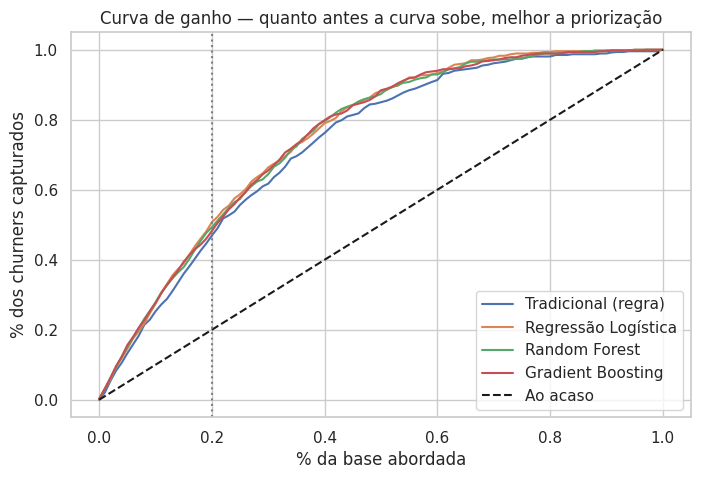

In [21]:
plt.figure(figsize=(8, 5))  # figura da curva de ganho
fracoes = np.linspace(0, 1, 101)  # frações da base de 0% a 100%
for nome, s in scores.items():  # para cada abordagem
    ordem = np.argsort(-(s + rng.random(len(s)) * 1e-6))  # ordena do maior para o menor risco
    acumulado = np.cumsum(y_arr[ordem]) / y_arr.sum()  # % acumulado de churners capturados conforme descemos a lista
    plt.plot(fracoes, np.interp(fracoes * len(y_arr), np.arange(1, len(y_arr) + 1), acumulado), label=nome)  # desenha a curva
plt.plot([0, 1], [0, 1], 'k--', label='Ao acaso')  # referência: escolher clientes aleatoriamente
plt.axvline(PCT_CAMPANHA, color='gray', linestyle=':')  # marca o tamanho da campanha
plt.xlabel('% da base abordada')  # eixo X
plt.ylabel('% dos churners capturados')  # eixo Y
plt.title('Curva de ganho — quanto antes a curva sobe, melhor a priorização')  # título
plt.legend()  # legenda
plt.show()  # exibe

## PAR 3 `[DIAGNÓSTICA]` — Quais fatores explicam o cancelamento?
- **Tradicional:** maior diferença de taxa de churn entre categorias de cada variável (olha uma variável por vez).
- **Inteligência:** *importância por permutação* — embaralhamos uma variável de cada vez e medimos quanto o modelo piora. Captura o efeito de cada variável **já descontado das outras** (ex.: fibra é cara, então parte do efeito de "mensalidade alta" pode ser na verdade "fibra").

In [22]:
amplitude = tabela_tradicional.groupby('variavel')['taxa_churn'].agg(lambda t: t.max() - t.min())  # para cada variável categórica: maior taxa − menor taxa
for col in colunas_numericas:  # para as numéricas, comparamos os quartis
    faixas = pd.qcut(treino[col], 4, duplicates='drop')  # divide a variável em 4 faixas de mesmo tamanho
    taxas = treino.groupby(faixas, observed=True)['Churn'].mean()  # taxa de churn em cada faixa
    amplitude[col] = taxas.max() - taxas.min()  # diferença entre a faixa mais e a menos arriscada
ranking_trad = amplitude.sort_values(ascending=False)  # ordena da variável mais "explicativa" para a menos

resultado_perm = permutation_importance(pipelines[melhor_modelo], X_teste, y_teste,  # embaralha cada coluna do teste e mede a perda
                                        scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=-1)  # usa AUC; repete 10 vezes para estabilidade
ranking_ia = pd.Series(resultado_perm.importances_mean, index=X_teste.columns).sort_values(ascending=False)  # importância média de cada variável

comparacao = pd.DataFrame({'Posição tradicional': ranking_trad.rank(ascending=False).astype(int),  # posição de cada variável no ranking tradicional
                           'Posição IA': ranking_ia.rank(ascending=False).astype(int),  # posição no ranking do modelo
                           'Amplitude churn (trad.)': ranking_trad,  # valor usado no ranking tradicional
                           'Queda de AUC (IA)': ranking_ia})  # valor usado no ranking do modelo
comparacao = comparacao.sort_values('Posição IA')  # ordena pelo ranking do modelo
comparacao.style.format({'Amplitude churn (trad.)': '{:.1%}', 'Queda de AUC (IA)': '{:.4f}'})  # exibe formatado

,Posição tradicional,Posição IA,Amplitude churn (trad.),Queda de AUC (IA)
Contract,2,1,39.7%,0.0794
tenure,1,2,41.6%,0.0713
TotalCharges,9,3,26.9%,0.0111
InternetService,3,4,34.8%,0.0096
MonthlyCharges,12,5,26.0%,0.0079
OnlineSecurity,4,6,34.7%,0.0078
PaymentMethod,8,7,30.4%,0.0061
MultipleLines,17,8,5.2%,0.0037
PaperlessBilling,13,9,18.2%,0.0037
TechSupport,5,10,34.7%,0.0034


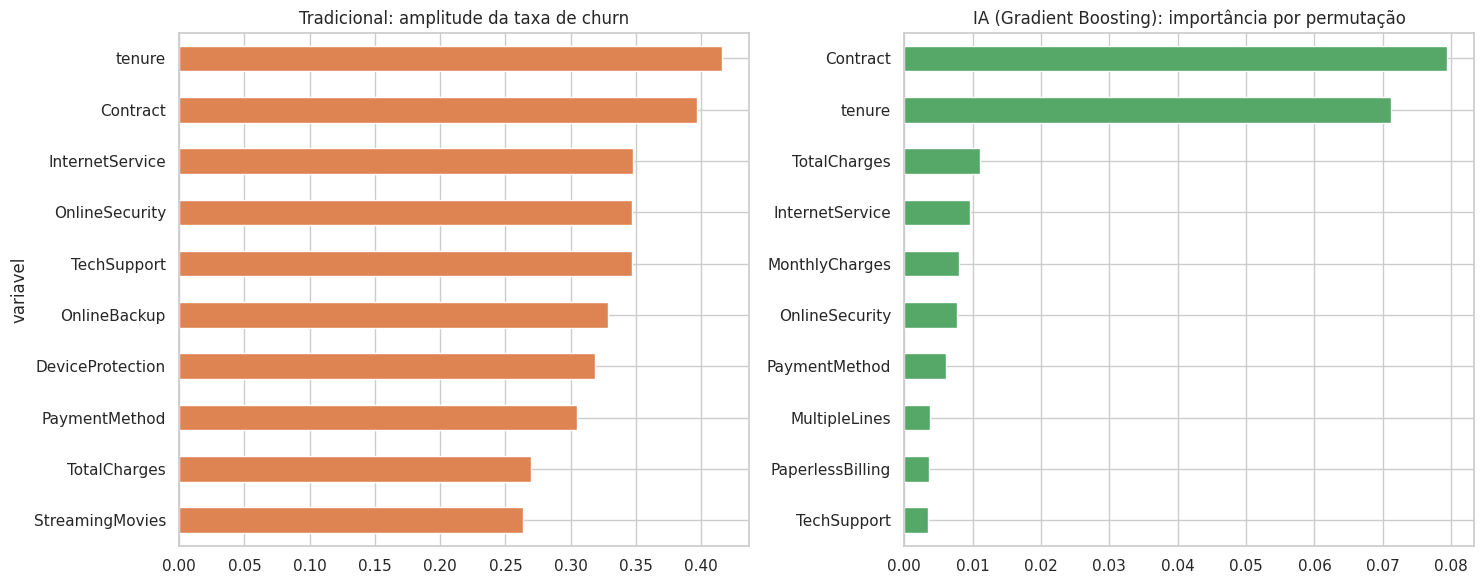

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 6))  # dois gráficos lado a lado
ranking_trad.head(10).iloc[::-1].plot(kind='barh', ax=eixos[0], color='#DD8452')  # top 10 tradicional (invertido para o maior ficar em cima)
eixos[0].set_title('Tradicional: amplitude da taxa de churn')  # título
ranking_ia.head(10).iloc[::-1].plot(kind='barh', ax=eixos[1], color='#55A868')  # top 10 do modelo
eixos[1].set_title(f'IA ({melhor_modelo}): importância por permutação')  # título
plt.tight_layout()  # ajusta espaçamento
plt.show()  # exibe

## PAR 4 `[DESCRITIVA]` — Como segmentar a base?
- **Tradicional:** faixas fixas de tempo de casa (0–12, 13–24, 25–48, 49+ meses).
- **Inteligência:** K-Means agrupa clientes parecidos considerando várias variáveis ao mesmo tempo.

Critério de comparação: um bom segmento para retenção é aquele que **separa bem quem tem alto e baixo risco**. Medimos isso pelo desvio padrão da taxa de churn entre segmentos (quanto maior, mais os segmentos diferenciam o risco), calculado no teste.

In [24]:
faixas_manuais = [-1, 12, 24, 48, 100]  # limites das faixas de tempo de casa
rotulos = ['0-12m', '13-24m', '25-48m', '49m+']  # nomes das faixas
seg_trad_teste = pd.cut(X_teste['tenure'], bins=faixas_manuais, labels=rotulos)  # aplica as faixas ao teste

K = 4  # mesmo número de segmentos que a abordagem manual, para comparação justa
segmentador = Pipeline([('prep', preprocessador), ('kmeans', KMeans(n_clusters=K, n_init=10, random_state=SEED))])  # pré-processa e agrupa
segmentador.fit(X_treino)  # aprende os grupos só com o treino (sem olhar o churn!)
seg_ia_teste = segmentador.predict(X_teste)  # atribui cada cliente do teste a um grupo

dados_prep_teste = segmentador.named_steps['prep'].transform(X_teste)  # dados do teste já transformados, para medir a qualidade do cluster
print('Silhueta do K-Means (−1 a 1, maior = grupos mais bem definidos): {:.3f}'.format(  # imprime a métrica de silhueta
    silhouette_score(dados_prep_teste, seg_ia_teste, random_state=SEED, sample_size=min(2000, len(X_teste)))))  # calcula sobre até 2000 clientes

perfil_trad = pd.DataFrame({'seg': seg_trad_teste, 'Churn': y_teste}).groupby('seg', observed=True)['Churn'].agg(['count', 'mean'])  # tamanho e churn de cada faixa manual
perfil_ia = pd.DataFrame({'seg': seg_ia_teste, 'Churn': y_teste}).groupby('seg')['Churn'].agg(['count', 'mean'])  # tamanho e churn de cada cluster
print('\nSegmentos tradicionais:'); print(perfil_trad.rename(columns={'count': 'clientes', 'mean': 'taxa_churn'}).round(3))  # mostra o perfil das faixas
print('\nSegmentos K-Means:'); print(perfil_ia.rename(columns={'count': 'clientes', 'mean': 'taxa_churn'}).round(3))  # mostra o perfil dos clusters
print('\nSeparação de risco (desvio da taxa de churn entre segmentos):')  # título da comparação
print(f'  Tradicional: {perfil_trad["mean"].std():.3f} | K-Means: {perfil_ia["mean"].std():.3f}')  # quanto maior, melhor separa o risco

Silhueta do K-Means (−1 a 1, maior = grupos mais bem definidos): 0.204

Segmentos tradicionais:
        clientes  taxa_churn
seg                         
0-12m        534       0.470
13-24m       272       0.327
25-48m       387       0.214
49m+         568       0.077

Segmentos K-Means:
     clientes  taxa_churn
seg                      
0         383       0.078
1         478       0.567
2         483       0.122
3         417       0.257

Separação de risco (desvio da taxa de churn entre segmentos):
  Tradicional: 0.167 | K-Means: 0.221


In [25]:
X_teste_perfil = X_teste.assign(cluster=seg_ia_teste, Churn=y_teste.values)  # junta o cluster e o churn aos dados do teste
perfil = X_teste_perfil.groupby('cluster').agg(  # descreve cada cluster com estatísticas fáceis de interpretar
    clientes=('Churn', 'size'),  # quantos clientes
    taxa_churn=('Churn', 'mean'),  # % que cancelou
    tempo_casa_medio=('tenure', 'mean'),  # tempo de casa médio
    mensalidade_media=('MonthlyCharges', 'mean'),  # mensalidade média
    pct_mensal=('Contract', lambda c: (c == 'Month-to-month').mean()),  # % com contrato mensal
    pct_fibra=('InternetService', lambda c: (c == 'Fiber optic').mean()))  # % com fibra
perfil.style.format({'taxa_churn': '{:.1%}', 'tempo_casa_medio': '{:.0f}', 'mensalidade_media': 'R$ {:.0f}',  # formata cada coluna
                     'pct_mensal': '{:.0%}', 'pct_fibra': '{:.0%}'}).background_gradient(subset=['taxa_churn'], cmap='Reds')  # pinta de vermelho os clusters mais arriscados

,clientes,taxa_churn,tempo_casa_medio,mensalidade_media,pct_mensal,pct_fibra
cluster,,,,,,
0,383,7.8%,32,R$ 21,33%,0%
1,478,56.7%,15,R$ 84,95%,99%
2,483,12.2%,59,R$ 91,20%,63%
3,417,25.7%,21,R$ 51,70%,0%


## PAR 5 `[PRESCRITIVA]` — Qual ação oferecer a cada cliente?
Prever quem vai sair não basta: o gestor precisa saber **o que fazer**. Aqui a pergunta deixa de ser "quem?" e vira "qual ação, para quem, com qual orçamento?".

**Cardápio de ações de retenção** (alavancas que a empresa controla e que apareceram como fatores de risco nos Pares 3 e 4):

| Ação | Para quem se aplica | O que muda no cliente | Custo por cliente (ilustrativo) |
|---|---|---|---|
| Migrar para contrato anual com desconto | Contrato mensal | `Contract` → One year | R$ 60 |
| Migrar para débito automático com bônus | Cheque eletrônico ou boleto | `PaymentMethod` → Credit card (automatic) | R$ 15 |
| Suporte técnico grátis | Tem internet e não tem suporte | `TechSupport` → Yes | R$ 35 |

**Prescrição tradicional:** regra de negócio única — oferecer contrato anual a todo cliente de contrato mensal sinalizado pela regra de risco, do maior para o menor risco, até acabar o orçamento.

**Prescrição inteligente (em 3 passos):**
1. **Simulação "e se?":** para cada cliente e cada ação possível, o modelo recalcula o risco como se a ação tivesse sido aceita.
2. **Valor esperado:** (queda de risco × chance de o cliente aceitar a oferta × receita futura) − custo da ação.
3. **Otimização sob orçamento:** escolhe a melhor ação de cada cliente e preenche o orçamento pelos clientes de maior retorno por real investido.

> ⚠️ **Limitação importante:** o modelo aprendeu *associações*, não *causas*. A simulação estima o efeito provável, mas o efeito real de cada ação deve ser confirmado com um **teste A/B** (oferecer a ação a um grupo e comparar com um grupo de controle) antes de escalar a campanha.

In [26]:
ORCAMENTO = 15000.0  # verba total da campanha de retenção, em R$ (ajuste para o seu caso)
TAXA_ADESAO = 0.50  # chance de o cliente aceitar a oferta quando abordado
# MESES_RETIDOS já foi definido no Par 2 e é reaproveitado aqui (horizonte de receita preservada)

acoes = {  # cardápio de ações: para cada uma, quem pode receber, o que muda e quanto custa
    'Contrato anual': {
        'aplica': lambda d: d['Contract'] == 'Month-to-month',  # só faz sentido para quem tem contrato mensal
        'muda': {'Contract': 'One year'},  # o que muda no cadastro do cliente se ele aceitar
        'custo': 60.0},  # custo por cliente abordado (desconto concedido)
    'Débito automático': {
        'aplica': lambda d: d['PaymentMethod'].isin(['Electronic check', 'Mailed check']),  # só para quem paga de forma manual
        'muda': {'PaymentMethod': 'Credit card (automatic)'},  # passa a pagar no automático
        'custo': 15.0},  # custo do bônus oferecido
    'Suporte técnico grátis': {
        'aplica': lambda d: (d['TechSupport'] == 'No') & (d['InternetService'] != 'No'),  # tem internet mas não tem suporte
        'muda': {'TechSupport': 'Yes'},  # passa a ter suporte
        'custo': 35.0}}  # custo de oferecer o serviço

modelo_presc = pipelines[melhor_modelo]  # usamos o melhor modelo do Par 1 como "simulador" de risco
risco_atual = modelo_presc.predict_proba(X_teste)[:, 1]  # risco atual de cada cliente do teste
receita_futura = X_teste['MonthlyCharges'].values * MESES_RETIDOS  # receita que o cliente gera se ficar

ganho_liquido = pd.DataFrame(index=X_teste.index)  # tabela: uma linha por cliente, uma coluna por ação
reducao_risco = pd.DataFrame(index=X_teste.index)  # tabela: quanto cada ação reduz o risco de cada cliente
for nome_acao, a in acoes.items():  # percorre cada ação do cardápio
    simulado = X_teste.copy()  # copia os clientes para não alterar os dados originais
    for coluna, novo_valor in a['muda'].items():  # aplica a mudança que a ação provoca
        simulado[coluna] = novo_valor  # ex.: Contract passa a ser 'One year'
    risco_novo = modelo_presc.predict_proba(simulado)[:, 1]  # o modelo recalcula o risco "e se o cliente aceitasse"
    queda = np.clip(risco_atual - risco_novo, 0, None)  # queda de risco (se o modelo indicar aumento, consideramos zero)
    valor = queda * TAXA_ADESAO * receita_futura - a['custo']  # valor esperado da ação: receita protegida − custo
    aplicavel = a['aplica'](X_teste).values  # True para clientes que podem receber a ação
    ganho_liquido[nome_acao] = np.where(aplicavel, valor, -np.inf)  # quem não pode receber fica com −infinito (nunca será escolhido)
    reducao_risco[nome_acao] = np.where(aplicavel, queda, 0.0)  # guarda a queda de risco para o relatório

ganho_liquido.replace(-np.inf, np.nan).describe().T[['count', 'mean', 'max']].style.format('{:.2f}')  # resumo: quantos clientes elegíveis e ganho médio/máximo por ação

,count,mean,max
Contrato anual,968.00,30.93,181.85
Débito automático,998.00,3.21,85.10
Suporte técnico grátis,888.00,-14.21,90.91


In [27]:
def executar_plano(candidatos, orcamento):  # preenche o orçamento seguindo a ordem de prioridade recebida
    escolhidos, gasto = [], 0.0  # lista de clientes selecionados e quanto já foi gasto
    for _, linha in candidatos.iterrows():  # percorre os candidatos na ordem de prioridade
        if gasto + linha['custo'] <= orcamento:  # se ainda cabe no orçamento
            escolhidos.append(linha)  # inclui o cliente no plano
            gasto += linha['custo']  # desconta o custo da ação
    return pd.DataFrame(escolhidos), gasto  # devolve o plano e o total gasto

# ---------- Prescrição INTELIGENTE ----------
melhor_acao = ganho_liquido.idxmax(axis=1)  # para cada cliente, a ação de maior valor esperado
melhor_valor = ganho_liquido.max(axis=1)  # o valor esperado dessa ação
cand_ia = pd.DataFrame({'acao': melhor_acao, 'ganho_esperado': melhor_valor,  # monta a lista de candidatos
                        'custo': [acoes[a]['custo'] for a in melhor_acao],  # custo da ação escolhida para cada cliente
                        'risco_atual': risco_atual}, index=X_teste.index)  # risco atual do cliente
cand_ia = cand_ia[cand_ia['ganho_esperado'] > 0]  # só vale abordar quem tem retorno esperado positivo
cand_ia['retorno_por_real'] = cand_ia['ganho_esperado'] / cand_ia['custo']  # ROI de cada abordagem
cand_ia = cand_ia.sort_values('retorno_por_real', ascending=False)  # prioriza quem dá mais retorno por real investido
plano_ia, gasto_ia = executar_plano(cand_ia, ORCAMENTO)  # monta o plano dentro do orçamento

# ---------- Prescrição TRADICIONAL ----------
sinalizados = (pontos_teste >= melhor_corte) & (X_teste['Contract'] == 'Month-to-month').values  # clientes de risco pela regra e com contrato mensal
cand_trad = pd.DataFrame({'acao': 'Contrato anual',  # todos recebem a mesma oferta
                          'ganho_esperado': ganho_liquido['Contrato anual'].values,  # valor esperado dessa oferta (estimado pelo mesmo simulador)
                          'custo': acoes['Contrato anual']['custo'],  # custo da oferta
                          'risco_atual': risco_atual,  # risco atual (só para o relatório)
                          'pontos': pontos_teste}, index=X_teste.index)[sinalizados]  # pontuação tradicional; fica só com os sinalizados
cand_trad = cand_trad.sort_values('pontos', ascending=False)  # prioriza pela pontuação de risco, como faria o analista
plano_trad, gasto_trad = executar_plano(cand_trad, ORCAMENTO)  # monta o plano dentro do mesmo orçamento

def resumo_plano(plano, gasto, nome):  # calcula os indicadores de cada plano
    ganho = plano['ganho_esperado'].sum() if len(plano) else 0.0  # ganho líquido esperado total
    retidos = sum(reducao_risco.loc[i, a] * TAXA_ADESAO for i, a in zip(plano.index, plano['acao'])) if len(plano) else 0.0  # nº esperado de clientes que deixam de cancelar
    return {'Plano': nome, 'Clientes abordados': len(plano),  # nome e quantidade de clientes
            'Investimento (R$)': gasto,  # quanto foi gasto
            'Clientes retidos (esperado)': retidos,  # quantos cancelamentos se espera evitar
            'Ganho líquido esperado (R$)': ganho,  # retorno líquido do plano
            'ROI': ganho / gasto if gasto else 0.0}  # retorno por real investido

tabela_par5 = pd.DataFrame([resumo_plano(plano_trad, gasto_trad, 'Tradicional (oferta única)'),  # resume o plano tradicional
                            resumo_plano(plano_ia, gasto_ia, 'Inteligência (ação otimizada)')]).set_index('Plano')  # resume o plano inteligente
tabela_par5.style.format({'Investimento (R$)': 'R$ {:,.0f}', 'Ganho líquido esperado (R$)': 'R$ {:,.0f}',  # formata valores em reais
                          'Clientes retidos (esperado)': '{:.1f}', 'ROI': '{:.1%}'}).highlight_max(color='#c6efce')  # formata e destaca o melhor

,Clientes abordados,Investimento (R$),Clientes retidos (esperado),Ganho líquido esperado (R$),ROI
Plano,,,,,
Tradicional (oferta única),250,"R$ 15,000",43.1,"R$ 25,727",171.5%
Inteligência (ação otimizada),304,"R$ 14,995",49.7,"R$ 33,341",222.3%


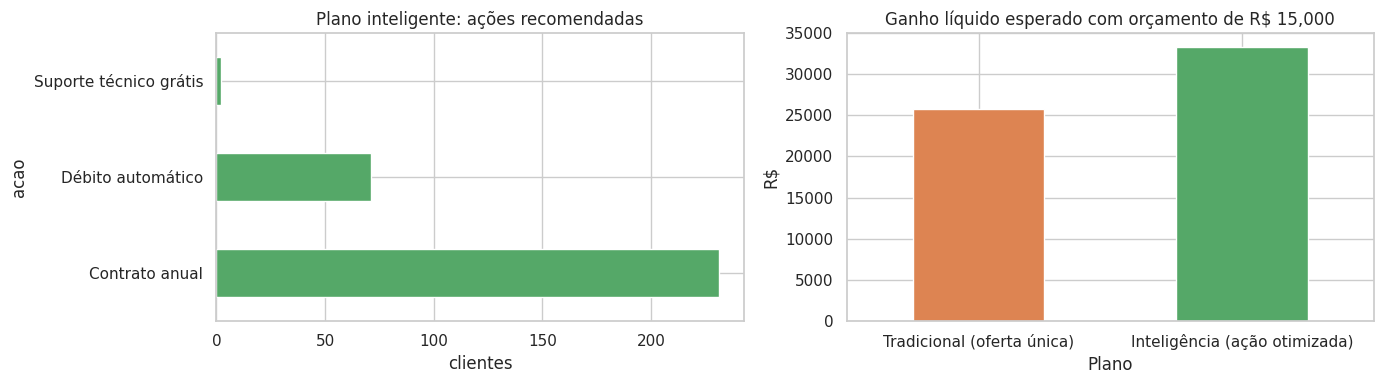

In [28]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))  # dois gráficos lado a lado
if len(plano_ia):  # se o plano inteligente selecionou alguém
    plano_ia['acao'].value_counts().plot(kind='barh', ax=eixos[0], color='#55A868')  # quantos clientes receberam cada ação
eixos[0].set_title('Plano inteligente: ações recomendadas')  # título
eixos[0].set_xlabel('clientes')  # eixo X
tabela_par5['Ganho líquido esperado (R$)'].plot(kind='bar', ax=eixos[1], color=['#DD8452', '#55A868'], rot=0)  # compara o ganho dos dois planos
eixos[1].set_title(f'Ganho líquido esperado com orçamento de R$ {ORCAMENTO:,.0f}')  # título
eixos[1].set_ylabel('R$')  # eixo Y
plt.tight_layout()  # ajusta espaçamento
plt.show()  # exibe

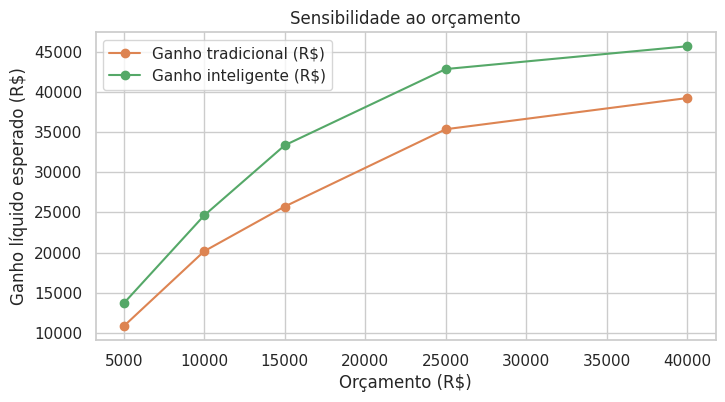

,Ganho tradicional (R$),Ganho inteligente (R$)
Orçamento (R$),,
5000,"R$ 10,845","R$ 13,687"
10000,"R$ 20,173","R$ 24,624"
15000,"R$ 25,727","R$ 33,341"
25000,"R$ 35,338","R$ 42,821"
40000,"R$ 39,218","R$ 45,654"


In [29]:
# Análise de sensibilidade: o plano inteligente continua vencendo se mudarmos o orçamento?
linhas = []  # lista para os resultados de cada orçamento
for orc in [5000, 10000, 15000, 25000, 40000]:  # orçamentos testados
    p_trad, g_trad = executar_plano(cand_trad, orc)  # plano tradicional com esse orçamento
    p_ia, g_ia = executar_plano(cand_ia, orc)  # plano inteligente com esse orçamento
    linhas.append({'Orçamento (R$)': orc,  # orçamento testado
                   'Ganho tradicional (R$)': p_trad['ganho_esperado'].sum() if len(p_trad) else 0,  # ganho do tradicional
                   'Ganho inteligente (R$)': p_ia['ganho_esperado'].sum() if len(p_ia) else 0})  # ganho do inteligente
sens = pd.DataFrame(linhas).set_index('Orçamento (R$)')  # monta a tabela
sens.plot(marker='o', figsize=(8, 4), title='Sensibilidade ao orçamento', color=['#DD8452', '#55A868'])  # desenha as duas curvas
plt.ylabel('Ganho líquido esperado (R$)')  # eixo Y
plt.show()  # exibe
sens.style.format('R$ {:,.0f}')  # mostra a tabela formatada

## Etapa final — Consolidando a constatação
A célula abaixo monta um placar automático com os resultados dos cinco pares.

In [30]:
placar = pd.DataFrame([  # tabela-resumo com um par por linha
    {'Par': '1. Quem vai cancelar (F1)',  # pergunta do par 1
     'Tradicional': tabela_par1.loc['Tradicional (regra)', 'F1'],  # resultado da regra
     'Inteligência': tabela_par1.loc[melhor_modelo, 'F1']},  # resultado do melhor modelo
    {'Par': '1. Capacidade de ordenar risco (AUC)',  # AUC do par 1
     'Tradicional': tabela_par1.loc['Tradicional (regra)', 'AUC'],  # AUC da regra
     'Inteligência': tabela_par1.loc[melhor_modelo, 'AUC']},  # AUC do modelo
    {'Par': '2. Churners capturados no top 20%',  # par 2
     'Tradicional': tabela_par2.loc['Tradicional (regra)', '% dos churners capturados'],  # cobertura da regra
     'Inteligência': tabela_par2.loc[melhor_modelo, '% dos churners capturados']},  # cobertura do modelo
    {'Par': '4. Separação de risco entre segmentos',  # par 4
     'Tradicional': perfil_trad['mean'].std(),  # separação das faixas manuais
     'Inteligência': perfil_ia['mean'].std()},  # separação do K-Means
    {'Par': '5. Ganho líquido esperado do plano (R$)',  # par 5 (prescritivo)
     'Tradicional': tabela_par5.loc['Tradicional (oferta única)', 'Ganho líquido esperado (R$)'],  # ganho do plano tradicional
     'Inteligência': tabela_par5.loc['Inteligência (ação otimizada)', 'Ganho líquido esperado (R$)']}]).set_index('Par')  # ganho do plano inteligente
placar['Ganho relativo'] = placar['Inteligência'] / placar['Tradicional'] - 1  # quanto a IA melhorou (ou piorou) em %
placar['Vencedor'] = np.where(placar['Inteligência'] > placar['Tradicional'], 'Inteligência', 'Tradicional')  # quem ganhou cada linha
placar.style.format({'Tradicional': '{:,.3f}', 'Inteligência': '{:,.3f}', 'Ganho relativo': '{:+.1%}'})  # exibe formatado

,Tradicional,Inteligência,Ganho relativo,Vencedor
Par,,,,
1. Quem vai cancelar (F1),0.615,0.630,+2.5%,Inteligência
1. Capacidade de ordenar risco (AUC),0.820,0.843,+2.8%,Inteligência
2. Churners capturados no top 20%,0.467,0.482,+3.2%,Inteligência
4. Separação de risco entre segmentos,0.167,0.221,+32.4%,Inteligência
5. Ganho líquido esperado do plano (R$),"25,726.504","33,340.966",+29.6%,Inteligência


In [31]:
# Resumo executivo gerado automaticamente a partir dos números do notebook
p_mcnemar = teste_mcnemar(y_teste.values, previsoes['Tradicional (regra)'], previsoes[melhor_modelo])[3]  # p-valor do melhor modelo contra a regra
t, ia = tabela_par1.loc['Tradicional (regra)'], tabela_par1.loc[melhor_modelo]  # métricas da regra e do melhor modelo
r5t, r5i = tabela_par5.iloc[0], tabela_par5.iloc[1]  # resultados dos planos tradicional e inteligente
print('RESUMO EXECUTIVO')  # título
print('=' * 70)  # linha separadora
print(f'DESCRITIVA : churn geral de {taxa_geral:.1%}; maiores riscos em {", ".join(tabela_tradicional.head(3)["categoria"].astype(str))}.')  # o que aconteceu
print(f'DIAGNÓSTICA: fatores mais importantes para o modelo: {", ".join(ranking_ia.head(3).index)}.')  # por que aconteceu
print(f'PREDITIVA  : {melhor_modelo} captura {ia["Recall"]:.0%} dos churners (regra: {t["Recall"]:.0%}), '  # o que vai acontecer
      f'F1 {ia["F1"]:.3f} vs {t["F1"]:.3f}, AUC {ia["AUC"]:.3f} vs {t["AUC"]:.3f}; McNemar p={p_mcnemar:.4f}.')  # com teste estatístico
print(f'PRESCRITIVA: com R$ {ORCAMENTO:,.0f}, o plano otimizado rende R$ {r5i["Ganho líquido esperado (R$)"]:,.0f} '  # o que fazer
      f'(ROI {r5i["ROI"]:.0%}) contra R$ {r5t["Ganho líquido esperado (R$)"]:,.0f} da oferta única (ROI {r5t["ROI"]:.0%}).')  # comparação com o tradicional
print('=' * 70)  # linha separadora
vitorias = (placar['Vencedor'] == 'Inteligência').sum()  # em quantos pares a IA venceu
print(f'Constatação: a inteligência superou a análise tradicional em {vitorias} de {len(placar)} indicadores.')  # conclusão geral

RESUMO EXECUTIVO
DESCRITIVA : churn geral de 26.5%; maiores riscos em Electronic check, Month-to-month, Fiber optic.
DIAGNÓSTICA: fatores mais importantes para o modelo: Contract, tenure, TotalCharges.
PREDITIVA  : Gradient Boosting captura 72% dos churners (regra: 79%), F1 0.630 vs 0.615, AUC 0.843 vs 0.820; McNemar p=0.0000.
PRESCRITIVA: com R$ 15,000, o plano otimizado rende R$ 33,341 (ROI 222%) contra R$ 25,727 da oferta única (ROI 172%).
Constatação: a inteligência superou a análise tradicional em 5 de 5 indicadores.


## Entregável do MVP — plano de ação exportável
O resultado prático da análise: uma lista pronta para o time comercial, com cada cliente, seu risco, a ação recomendada e o ganho esperado. O arquivo é salvo como CSV e baixado automaticamente no Colab.

In [32]:
plano_export = plano_ia.copy()  # parte do plano inteligente
plano_export['reducao_risco'] = [reducao_risco.loc[i, a] for i, a in zip(plano_export.index, plano_export['acao'])]  # quanto a ação reduz o risco do cliente
plano_export = plano_export.join(X_teste[['tenure', 'Contract', 'PaymentMethod', 'MonthlyCharges']])  # acrescenta dados de cadastro úteis para o atendente
plano_export['prioridade'] = range(1, len(plano_export) + 1)  # ordem de abordagem (1 = ligar primeiro)
plano_export = plano_export[['prioridade', 'risco_atual', 'acao', 'reducao_risco', 'custo', 'ganho_esperado',  # escolhe e ordena as colunas
                             'tenure', 'Contract', 'PaymentMethod', 'MonthlyCharges']]
plano_export.to_csv('plano_de_acao_retencao.csv', index_label='id_cliente', float_format='%.4f')  # salva o CSV
print(f'{len(plano_export)} clientes no plano. Arquivo salvo: plano_de_acao_retencao.csv')  # confirma

try:  # tenta baixar o arquivo (só funciona dentro do Colab)
    from google.colab import files  # ferramenta de download do Colab
    files.download('plano_de_acao_retencao.csv')  # dispara o download no navegador
except ImportError:  # fora do Colab não existe esse módulo
    pass  # nesse caso o arquivo fica salvo na pasta atual

plano_export.head(10).style.format({'risco_atual': '{:.1%}', 'reducao_risco': '{:.1%}',  # mostra os 10 primeiros com formatação
                                    'custo': 'R$ {:.0f}', 'ganho_esperado': 'R$ {:.0f}', 'MonthlyCharges': 'R$ {:.0f}'})

304 clientes no plano. Arquivo salvo: plano_de_acao_retencao.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,prioridade,risco_atual,acao,reducao_risco,custo,ganho_esperado,tenure,Contract,PaymentMethod,MonthlyCharges
2699,1,53.9%,Débito automático,17.3%,R$ 15,R$ 85,34,Month-to-month,Electronic check,R$ 96
574,2,56.8%,Débito automático,14.0%,R$ 15,R$ 78,28,Month-to-month,Electronic check,R$ 111
1630,3,60.6%,Débito automático,13.9%,R$ 15,R$ 71,38,Month-to-month,Electronic check,R$ 103
38,4,56.0%,Débito automático,13.1%,R$ 15,R$ 69,34,Month-to-month,Electronic check,R$ 106
5133,5,67.6%,Débito automático,13.3%,R$ 15,R$ 68,24,Month-to-month,Electronic check,R$ 104
4448,6,61.5%,Débito automático,13.8%,R$ 15,R$ 68,30,Month-to-month,Electronic check,R$ 100
8,7,65.1%,Débito automático,12.7%,R$ 15,R$ 65,28,Month-to-month,Electronic check,R$ 105
4121,8,56.8%,Débito automático,14.0%,R$ 15,R$ 65,27,Month-to-month,Electronic check,R$ 96
505,9,57.7%,Débito automático,14.0%,R$ 15,R$ 64,20,Month-to-month,Electronic check,R$ 94
3864,10,59.0%,Débito automático,13.1%,R$ 15,R$ 64,30,Month-to-month,Electronic check,R$ 100


### Como escrever a conclusão (roteiro)
1. **Par 1:** cite F1 e AUC das duas abordagens e o p-valor de McNemar. Ganho significativo → a IA melhora a *resposta*; não significativo → a regra tradicional, por ser mais simples, pode ser suficiente.
2. **Par 2:** traduza em dinheiro: "com o mesmo orçamento, o modelo coloca X churners a mais na lista, gerando R$ Y a mais".
3. **Par 3:** aponte onde os rankings concordam (validação mútua) e onde discordam — é aí que a IA "corrige" correlações enganosas da análise uma-variável-por-vez.
4. **Par 4:** compare a separação de risco e descreva os perfis de cluster: a IA tende a achar segmentos que misturam várias características (ex.: "novos, contrato mensal, fibra") que faixas de uma variável só não enxergam.
5. **Par 5:** mostre que o plano otimizado não só escolhe *quem* abordar, mas *com qual ação* — e quanto isso rende a mais com o mesmo orçamento. Use a análise de sensibilidade para mostrar se a vantagem se mantém.
6. **Limitações:** uma única base, premissas financeiras ilustrativas, modelos sem ajuste fino de hiperparâmetros, e a simulação prescritiva estima associações, não causas — o próximo passo seria um teste A/B das ações. A IA complementa, não substitui, a leitura de negócio: foi a análise tradicional que gerou as hipóteses e torna o resultado explicável.